In [2]:
import os
path = "../data/FUNSD/dataset/training_data/images"
print(os.path.exists(path))
print(os.listdir(path)[:5])

True
['0000971160.png', '0000989556.png', '0000990274.png', '0000999294.png', '0001118259.png']


In [3]:
import os
path = "../data/FUNSD/dataset/training_data/images"
all_files = os.listdir(path)
print("Total images:", len(all_files))

Total images: 149


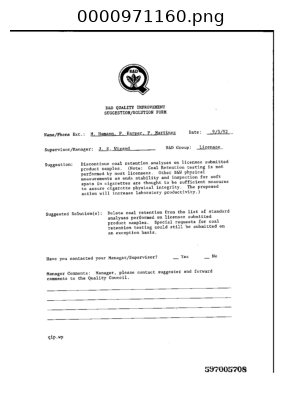

In [4]:
import matplotlib.pyplot as plt
import cv2

img_path = os.path.join(path, all_files[0])
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title(all_files[0])
plt.axis('off')
plt.show()

In [5]:
#phase 2
import json

# Annotations folder check karo
ann_path = "../data/FUNSD/dataset/training_data/annotations"
ann_files = os.listdir(ann_path)
print("Total annotation files:", len(ann_files))
print("Pehli file:", ann_files[0])

# Ek annotation file kholo aur dekho andar kya hai
with open(os.path.join(ann_path, ann_files[0]), 'r') as f:
    data = json.load(f)

print(json.dumps(data['form'][:3], indent=2))  # pehle 3 entries dikhao

Total annotation files: 149
Pehli file: 0000971160.json
[
  {
    "box": [
      292,
      91,
      376,
      175
    ],
    "text": "R&D",
    "label": "other",
    "words": [
      {
        "box": [
          292,
          91,
          376,
          175
        ],
        "text": "R&D"
      }
    ],
    "linking": [],
    "id": 0
  },
  {
    "box": [
      219,
      316,
      225,
      327
    ],
    "text": ":",
    "label": "question",
    "words": [
      {
        "box": [
          219,
          316,
          225,
          327
        ],
        "text": ":"
      }
    ],
    "linking": [],
    "id": 1
  },
  {
    "box": [
      95,
      355,
      169,
      370
    ],
    "text": "Suggestion:",
    "label": "question",
    "words": [
      {
        "box": [
          95,
          355,
          169,
          370
        ],
        "text": "Suggestion:"
      }
    ],
    "linking": [
      [
        2,
        16
      ]
    ],
    "id": 2
  }
]


In [6]:
labels = set()
for entry in data['form']:
    labels.add(entry['label'])
print("Label types:", labels)

Label types: {'question', 'answer', 'other', 'header'}


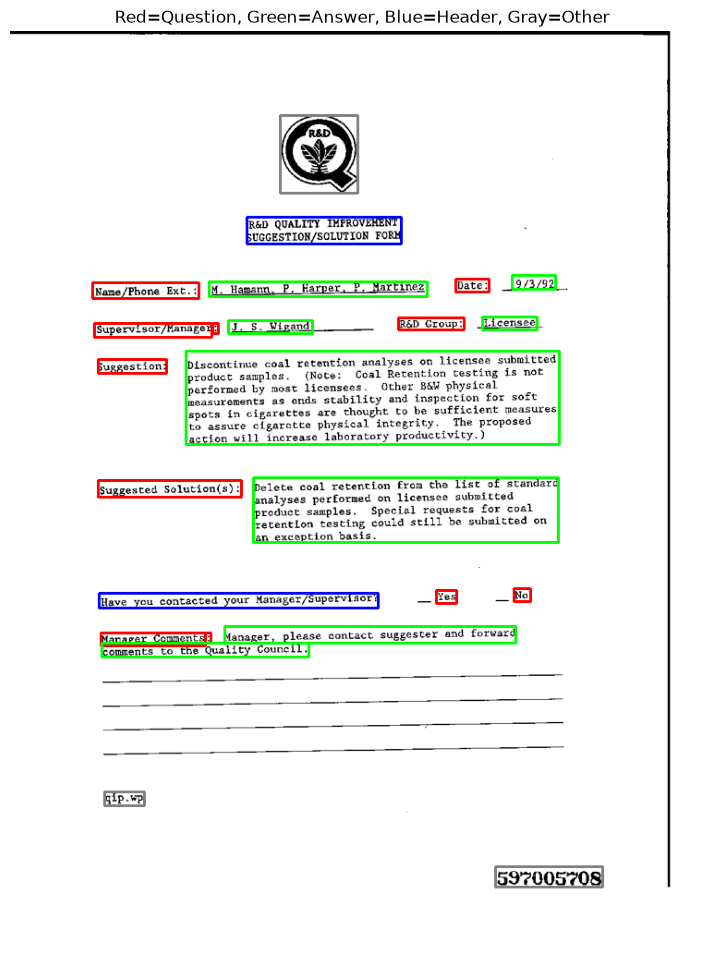

In [7]:
import cv2
import matplotlib.pyplot as plt

img_path = os.path.join(path, all_files[0].replace('.json', '.png'))
# Agar naam match nahi kare to ye use karo:
img_name = ann_files[0].replace('.json', '.png')
img_path = os.path.join(path, img_name)

img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

color_map = {"question": (255,0,0), "answer": (0,255,0), "header": (0,0,255), "other": (128,128,128)}

for entry in data['form']:
    x0, y0, x1, y1 = entry['box']
    color = color_map.get(entry['label'], (0,0,0))
    cv2.rectangle(img_rgb, (x0,y0), (x1,y1), color, 2)

plt.figure(figsize=(10,12))
plt.imshow(img_rgb)
plt.axis('off')
plt.title("Red=Question, Green=Answer, Blue=Header, Gray=Other")
plt.show()

In [8]:
import json

total_forms = len(ann_files)
total_entries = 0
label_counts = {"question": 0, "answer": 0, "header": 0, "other": 0}

for file in ann_files:
    with open(os.path.join(ann_path, file), 'r', encoding='utf-8') as f:
        form_data = json.load(f)
    for entry in form_data['form']:
        total_entries += 1
        label_counts[entry['label']] += 1

print("Total Forms:", total_forms)
print("Total Text Blocks:", total_entries)
print("Average blocks per form:", round(total_entries / total_forms, 2))
print("\nLabel-wise breakdown:")
for label, count in label_counts.items():
    print(f"  {label}: {count}")

Total Forms: 149
Total Text Blocks: 7411
Average blocks per form: 49.74

Label-wise breakdown:
  question: 3266
  answer: 2802
  header: 441
  other: 902


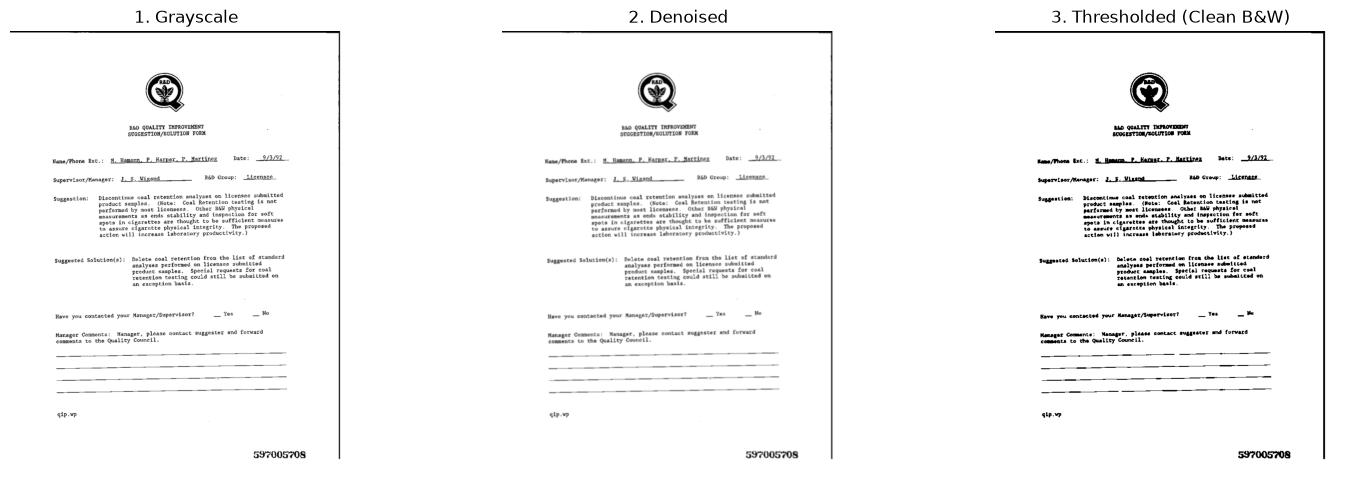

In [9]:
#Ab Step 2 — Image Preprocessing
import cv2
import matplotlib.pyplot as plt

# Original image load karo
img_name = ann_files[0].replace('.json', '.png')
img_path = os.path.join(path, img_name)
img = cv2.imread(img_path)

# Step 1: Grayscale mein convert karo
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 2: Noise remove karo (thoda blur karke)
denoised = cv2.GaussianBlur(gray, (3,3), 0)

# Step 3: Thresholding (text ko aur clear banana - black/white)
_, thresh = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Sabko side-by-side dikhao
fig, axes = plt.subplots(1, 3, figsize=(18,6))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title("1. Grayscale")
axes[0].axis('off')

axes[1].imshow(denoised, cmap='gray')
axes[1].set_title("2. Denoised")
axes[1].axis('off')

axes[2].imshow(thresh, cmap='gray')
axes[2].set_title("3. Thresholded (Clean B&W)")
axes[2].axis('off')

plt.show()

In [10]:
#IAM
#IAM
import pandas as pd
import os

iam_path = "../data/IAM"
train_csv = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))
print("Total training samples:", len(train_csv))
print(train_csv.head())

Total training samples: 330961
          FILENAME   IDENTITY
0  TRAIN_00001.jpg  BALTHAZAR
1  TRAIN_00002.jpg      SIMON
2  TRAIN_00003.jpg      BENES
3  TRAIN_00004.jpg    LA LOVE
4  TRAIN_00005.jpg     DAPHNE


In [11]:
import cv2
import os

def preprocess_image(img):
    """CNN preprocessing pipeline: grayscale -> denoise -> threshold"""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    denoised = cv2.GaussianBlur(gray, (3,3), 0)
    _, thresh = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return thresh

# ---- FUNSD preprocessing ----
funsd_output = "../data/FUNSD/preprocessed"
os.makedirs(funsd_output, exist_ok=True)

count = 0
for img_file in all_files:
    img = cv2.imread(os.path.join(path, img_file))
    if img is None:
        continue
    processed = preprocess_image(img)
    cv2.imwrite(os.path.join(funsd_output, img_file), processed)
    count += 1
print(f"FUNSD: {count} images preprocessed.")

# ---- IAM preprocessing (sirf pehli 200 images, poora dataset bahut bada hai) ----
iam_train_folder = os.path.join(iam_path, "train_v2", "train")
iam_output = "../data/IAM/preprocessed"
os.makedirs(iam_output, exist_ok=True)

iam_files = os.listdir(iam_train_folder)[:200]  # pehle 200 images (test ke liye)
count2 = 0
for img_file in iam_files:
    img = cv2.imread(os.path.join(iam_train_folder, img_file))
    if img is None:
        continue
    processed = preprocess_image(img)
    cv2.imwrite(os.path.join(iam_output, img_file), processed)
    count2 += 1
print(f"IAM: {count2} images preprocessed.")

FUNSD: 149 images preprocessed.
IAM: 200 images preprocessed.


In [12]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")

CUDA available: True
GPU Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [13]:
import os
import pandas as pd
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# IAM training CSV load karo
iam_train_folder = os.path.join(iam_path, "train_v2", "train")
train_csv = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))

# NaN/missing labels hatao
train_csv = train_csv.dropna(subset=['IDENTITY'])
train_csv = train_csv[train_csv['IDENTITY'] != 'UNREADABLE']

print("Clean samples:", len(train_csv))
print(train_csv.head())

# Saare unique characters nikalo (jo bhi text mein aa sakte hain)
all_text = "".join(train_csv['IDENTITY'].astype(str).tolist())
unique_chars = sorted(set(all_text))
print("Total unique characters:", len(unique_chars))
print("Characters:", unique_chars)

Clean samples: 330294
          FILENAME   IDENTITY
0  TRAIN_00001.jpg  BALTHAZAR
1  TRAIN_00002.jpg      SIMON
2  TRAIN_00003.jpg      BENES
3  TRAIN_00004.jpg    LA LOVE
4  TRAIN_00005.jpg     DAPHNE
Total unique characters: 50
Characters: [' ', "'", '-', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '`', 'a', 'b', 'c', 'e', 'f', 'g', 'h', 'i', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'y', 'z']


In [14]:
# Character to number mapping (model numbers samajhta hai, letters nahi)
char_to_idx = {char: idx + 1 for idx, char in enumerate(unique_chars)}  # 0 reserved for blank (CTC ke liye)
idx_to_char = {idx + 1: char for idx, char in enumerate(unique_chars)}
num_classes = len(unique_chars) + 1  # +1 blank token ke liye

print("Total classes (including blank):", num_classes)

IMG_HEIGHT = 32
IMG_WIDTH = 128

class IAMDataset(Dataset):
    def __init__(self, dataframe, img_folder):
        self.data = dataframe.reset_index(drop=True)
        self.img_folder = img_folder

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.img_folder, row['FILENAME'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if img is None:
            img = np.zeros((IMG_HEIGHT, IMG_WIDTH), dtype=np.uint8)
        else:
            img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
        
        img = img.astype(np.float32) / 255.0
        img = torch.tensor(img).unsqueeze(0)  # channel dimension add karo
        
        label_text = str(row['IDENTITY'])
        label = [char_to_idx[c] for c in label_text if c in char_to_idx]
        label = torch.tensor(label, dtype=torch.long)
        
        return img, label, len(label)

print("Dataset class ready!")

Total classes (including blank): 51
Dataset class ready!


In [15]:
#CRNN Model Architecture
import torch.nn as nn

class CRNN(nn.Module):
    def __init__(self, num_classes):
        super(CRNN, self).__init__()
        
        # CNN Part - image se visual features nikalta hai
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 32x128 -> 16x64
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 16x64 -> 8x32
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d((2,1), (2,1)),  # 8x32 -> 4x32
            
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        
        # RNN Part - features ko sequence mein padh ke text predict karta hai
        self.rnn = nn.LSTM(input_size=128*4, hidden_size=256, num_layers=2, 
                            bidirectional=True, batch_first=True)
        
        self.fc = nn.Linear(256*2, num_classes)
    
    def forward(self, x):
        # CNN se features nikalo
        conv_out = self.cnn(x)  # shape: (batch, channels, height, width)
        batch, channels, height, width = conv_out.size()
        
        # Reshape karo RNN ke liye: (batch, width, channels*height)
        conv_out = conv_out.permute(0, 3, 1, 2)  # (batch, width, channels, height)
        conv_out = conv_out.reshape(batch, width, channels * height)
        
        # RNN se sequence process karo
        rnn_out, _ = self.rnn(conv_out)
        
        # Final prediction (har timestep ke liye character probability)
        output = self.fc(rnn_out)
        output = output.permute(1, 0, 2)  # CTC loss ke liye format: (seq_len, batch, num_classes)
        
        return output

# Model banao aur GPU pe bhejo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CRNN(num_classes).to(device)
print("Model ready on:", device)
print(model)

Model ready on: cuda
CRNN(
  (cnn): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
  )
  (rnn): LSTM(512, 256, num_layers=2, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=512, out_features=51, bias=True)
)


In [16]:
#DataLoader banao + Training Loop
from torch.nn.utils.rnn import pad_sequence
import torch.optim as optim

# Batch banane ka tarika (kyunki har image ka label alag length ka hai)
def collate_fn(batch):
    images, labels, label_lengths = zip(*batch)
    images = torch.stack(images)
    labels_concat = torch.cat(labels)
    label_lengths = torch.tensor(label_lengths, dtype=torch.long)
    return images, labels_concat, label_lengths

# Chote subset pe pehle test karte hain (5000 samples) - poora dataset baad mein
small_train = train_csv.sample(5000, random_state=42).reset_index(drop=True)

train_dataset = IAMDataset(small_train, iam_train_folder)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)

print("Total batches:", len(train_loader))

# Loss function aur optimizer
criterion = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training setup ready!")

Total batches: 157
Training setup ready!


In [17]:
#Training Loop (Model ko sikhana)
import time

num_epochs = 5  # pehle test ke liye kam epochs

model.train()
for epoch in range(num_epochs):
    start_time = time.time()
    total_loss = 0
    
    for batch_idx, (images, labels, label_lengths) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        label_lengths = label_lengths.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)  # shape: (seq_len, batch, num_classes)
        outputs = outputs.log_softmax(2)
        
        input_lengths = torch.full(size=(images.size(0),), fill_value=outputs.size(0), dtype=torch.long).to(device)
        
        loss = criterion(outputs, labels, input_lengths, label_lengths)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
        if batch_idx % 20 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Batch {batch_idx}/{len(train_loader)}, Loss: {loss.item():.4f}")
    
    avg_loss = total_loss / len(train_loader)
    epoch_time = time.time() - start_time
    print(f"===> Epoch {epoch+1} complete. Avg Loss: {avg_loss:.4f}, Time: {epoch_time:.1f}s\n")

print("Training complete!")

Epoch 1/5, Batch 0/157, Loss: 15.8777
Epoch 1/5, Batch 20/157, Loss: 3.2554
Epoch 1/5, Batch 40/157, Loss: 3.2438
Epoch 1/5, Batch 60/157, Loss: 3.2833
Epoch 1/5, Batch 80/157, Loss: 3.2808
Epoch 1/5, Batch 100/157, Loss: 3.2226
Epoch 1/5, Batch 120/157, Loss: 3.2220
Epoch 1/5, Batch 140/157, Loss: 3.0753
===> Epoch 1 complete. Avg Loss: 3.5014, Time: 94.2s

Epoch 2/5, Batch 0/157, Loss: 3.0637
Epoch 2/5, Batch 20/157, Loss: 3.1022
Epoch 2/5, Batch 40/157, Loss: 3.2343
Epoch 2/5, Batch 60/157, Loss: 3.1785
Epoch 2/5, Batch 80/157, Loss: 3.1070
Epoch 2/5, Batch 100/157, Loss: 3.0873
Epoch 2/5, Batch 120/157, Loss: 3.1688
Epoch 2/5, Batch 140/157, Loss: 2.9971
===> Epoch 2 complete. Avg Loss: 3.1306, Time: 12.7s

Epoch 3/5, Batch 0/157, Loss: 3.1328
Epoch 3/5, Batch 20/157, Loss: 3.1686
Epoch 3/5, Batch 40/157, Loss: 3.0728
Epoch 3/5, Batch 60/157, Loss: 3.0999
Epoch 3/5, Batch 80/157, Loss: 3.1725
Epoch 3/5, Batch 100/157, Loss: 2.9994
Epoch 3/5, Batch 120/157, Loss: 3.1413
Epoch 3/5, B

In [18]:
def decode_prediction(output):
    """Model ke output ko text mein convert karta hai"""
    output = output.permute(1, 0, 2)  # (batch, seq_len, classes)
    pred_indices = torch.argmax(output, dim=2)
    
    texts = []
    for pred in pred_indices:
        pred = pred.cpu().numpy()
        text = ""
        prev = 0
        for p in pred:
            if p != 0 and p != prev:  # blank aur duplicate hatao (CTC decoding)
                text += idx_to_char.get(p, "")
            prev = p
        texts.append(text)
    return texts

# Ek sample test karo
model.eval()
test_img, test_label, _ = train_dataset[0]
actual_text = small_train.iloc[0]['IDENTITY']

with torch.no_grad():
    test_img_batch = test_img.unsqueeze(0).to(device)
    output = model(test_img_batch)
    predicted_text = decode_prediction(output)

print("Actual text:", actual_text)
print("Predicted text:", predicted_text[0])

Actual text: JEGO
Predicted text: A


In [19]:
#Fix — Learning Rate Kam Karo + Gradient Clipping Add Karo
model = CRNN(num_classes).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.0005)  # kam learning rate
criterion = nn.CTCLoss(blank=0, zero_infinity=True)

num_epochs = 25
model.train()
for epoch in range(num_epochs):
    start_time = time.time()
    total_loss = 0
    
    for batch_idx, (images, labels, label_lengths) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)
        label_lengths = label_lengths.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        outputs = outputs.log_softmax(2)
        
        input_lengths = torch.full(size=(images.size(0),), fill_value=outputs.size(0), dtype=torch.long).to(device)
        loss = criterion(outputs, labels, input_lengths, label_lengths)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)  # gradient explosion rokta hai
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    epoch_time = time.time() - start_time
    print(f"Epoch {epoch+1}/{num_epochs} - Avg Loss: {avg_loss:.4f} - Time: {epoch_time:.1f}s")

print("Training complete!")
torch.save(model.state_dict(), "../models/crnn_model.pth")
print("Model saved!")

Epoch 1/25 - Avg Loss: 3.6524 - Time: 12.9s
Epoch 2/25 - Avg Loss: 3.1151 - Time: 12.6s
Epoch 3/25 - Avg Loss: 3.0682 - Time: 12.4s
Epoch 4/25 - Avg Loss: 3.0386 - Time: 12.6s
Epoch 5/25 - Avg Loss: 3.0237 - Time: 12.6s
Epoch 6/25 - Avg Loss: 3.0173 - Time: 12.6s
Epoch 7/25 - Avg Loss: 3.0143 - Time: 13.3s
Epoch 8/25 - Avg Loss: 3.0111 - Time: 12.9s
Epoch 9/25 - Avg Loss: 2.9385 - Time: 12.8s
Epoch 10/25 - Avg Loss: 2.8795 - Time: 13.2s
Epoch 11/25 - Avg Loss: 2.8457 - Time: 12.8s
Epoch 12/25 - Avg Loss: 2.8180 - Time: 12.6s
Epoch 13/25 - Avg Loss: 2.8191 - Time: 12.7s
Epoch 14/25 - Avg Loss: 2.7708 - Time: 12.9s
Epoch 15/25 - Avg Loss: 2.7349 - Time: 12.6s
Epoch 16/25 - Avg Loss: 2.6901 - Time: 14.1s
Epoch 17/25 - Avg Loss: 2.6251 - Time: 12.8s
Epoch 18/25 - Avg Loss: 2.5231 - Time: 12.6s
Epoch 19/25 - Avg Loss: 2.4188 - Time: 12.5s
Epoch 20/25 - Avg Loss: 2.3076 - Time: 12.6s
Epoch 21/25 - Avg Loss: 2.2008 - Time: 12.6s
Epoch 22/25 - Avg Loss: 2.0609 - Time: 12.4s
Epoch 23/25 - Avg L

In [20]:
val_csv = pd.read_csv(os.path.join(iam_path, "written_name_validation_v2.csv"))
val_csv = val_csv.dropna(subset=['IDENTITY'])
val_csv = val_csv[val_csv['IDENTITY'] != 'UNREADABLE']

val_folder = os.path.join(iam_path, "validation_v2", "validation")
val_sample = val_csv.sample(20, random_state=1).reset_index(drop=True)
val_dataset = IAMDataset(val_sample, val_folder)

correct = 0
model.eval()
for i in range(20):
    test_img, _, _ = val_dataset[i]
    actual_text = val_sample.iloc[i]['IDENTITY']
    
    with torch.no_grad():
        test_img_batch = test_img.unsqueeze(0).to(device)
        output = model(test_img_batch)
        predicted_text = decode_prediction(output)
    
    match = "✅" if predicted_text[0].upper() == str(actual_text).upper() else "❌"
    if match == "✅":
        correct += 1
    print(f"{match} Actual: {actual_text:15s} | Predicted: {predicted_text[0]}")

print(f"\nAccuracy: {correct}/20 = {correct/20*100:.1f}%")

❌ Actual: MARIAMA         | Predicted: TALAN
❌ Actual: LAARAS          | Predicted: CAAE
❌ Actual: JUSTINE         | Predicted: JUTINE
❌ Actual: STIEVENARD      | Predicted: DTTENEANRN
❌ Actual: NICOLAS         | Predicted: ILEINN
❌ Actual: HUGOLIN         | Predicted: BUSOLIN
❌ Actual: BARBOT          | Predicted: BONSOT
❌ Actual: IVARS           | Predicted: CART
❌ Actual: TRUFAUT         | Predicted: TAUIOUT
❌ Actual: THEO            | Predicted: THLO
❌ Actual: POURRET         | Predicted: POUSRET
❌ Actual: MARTIN          | Predicted: MANTIN
❌ Actual: GIBERT          | Predicted: DIIAT
❌ Actual: ROMERO          | Predicted: PORCAE
❌ Actual: KYLIAN          | Predicted: BALISN
❌ Actual: MATHIS          | Predicted: MATTTHIE
❌ Actual: VICTOR          | Predicted: PILIOR
❌ Actual: JULIETTE        | Predicted: CULISTTE
❌ Actual: GODET           | Predicted: GOROT
❌ Actual: SEBASTIEN       | Predicted: DENETTEN

Accuracy: 0/20 = 0.0%


In [21]:
print(model)
print("Device:", device)

CRNN(
  (cnn): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
  )
  (rnn): LSTM(512, 256, num_layers=2, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=512, out_features=51, bias=True)
)
Device: cuda


In [22]:
import os
import pandas as pd
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Paths
iam_path = "../data/IAM"
path = "../data/FUNSD/dataset/training_data/images"
ann_path = "../data/FUNSD/dataset/training_data/annotations"
all_files = os.listdir(path)
ann_files = os.listdir(ann_path)

# IAM setup
train_csv = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))
train_csv = train_csv.dropna(subset=['IDENTITY'])
train_csv = train_csv[train_csv['IDENTITY'] != 'UNREADABLE']

all_text = "".join(train_csv['IDENTITY'].astype(str).tolist())
unique_chars = sorted(set(all_text))
char_to_idx = {char: idx + 1 for idx, char in enumerate(unique_chars)}
idx_to_char = {idx + 1: char for idx, char in enumerate(unique_chars)}
num_classes = len(unique_chars) + 1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# CRNN class definition (zaroori hai model banane se pehle)
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super(CRNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d((2,1), (2,1)),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
        )
        self.rnn = nn.LSTM(input_size=128*4, hidden_size=256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(256*2, num_classes)
    
    def forward(self, x):
        conv_out = self.cnn(x)
        batch, channels, height, width = conv_out.size()
        conv_out = conv_out.permute(0, 3, 1, 2)
        conv_out = conv_out.reshape(batch, width, channels * height)
        rnn_out, _ = self.rnn(conv_out)
        output = self.fc(rnn_out)
        output = output.permute(1, 0, 2)
        return output

# Trained model load karo (training NAHI karni)
model = CRNN(num_classes).to(device)
model.load_state_dict(torch.load("../models/crnn_model.pth"))
model.eval()

print("Setup complete! Trained model loaded from disk.")
print("Device:", device)

Setup complete! Trained model loaded from disk.
Device: cuda


In [23]:
#RAG Pipeline — Step 1: FUNSD Text Extract Karo Ek Organized Format Mein
import json

# Saare 149 forms ka text ek jagah organize karo
all_documents = []  # har entry ek chunk of text hogi (metadata ke saath)

for file in ann_files:
    with open(os.path.join(ann_path, file), 'r', encoding='utf-8') as f:
        form_data = json.load(f)
    
    doc_id = file.replace('.json', '')
    
    for entry in form_data['form']:
        if entry['text'].strip() == "":
            continue
        all_documents.append({
            "doc_id": doc_id,
            "text": entry['text'],
            "label": entry['label'],
            "id": entry['id']
        })

print("Total text chunks extracted:", len(all_documents))
print("\nSample entries:")
for doc in all_documents[:5]:
    print(doc)

Total text chunks extracted: 7259

Sample entries:
{'doc_id': '0000971160', 'text': 'R&D', 'label': 'other', 'id': 0}
{'doc_id': '0000971160', 'text': ':', 'label': 'question', 'id': 1}
{'doc_id': '0000971160', 'text': 'Suggestion:', 'label': 'question', 'id': 2}
{'doc_id': '0000971160', 'text': 'Date:', 'label': 'question', 'id': 3}
{'doc_id': '0000971160', 'text': 'Licensee', 'label': 'answer', 'id': 4}


In [24]:
#Step 2: Embeddings Banao (Text Ko "Searchable" Banao)
from sentence_transformers import SentenceTransformer
import numpy as np

# Pretrained embedding model load karo (chota aur fast model)
embed_model = SentenceTransformer('all-MiniLM-L6-v2')

# Saare texts ki list banao
texts = [doc['text'] for doc in all_documents]

# Embeddings generate karo (ye thoda time lega, ~1-2 minute)
print("Generating embeddings...")
embeddings = embed_model.encode(texts, show_progress_bar=True)

print("Embeddings shape:", embeddings.shape)
print("Done!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Generating embeddings...


Batches:   0%|          | 0/227 [00:00<?, ?it/s]

Embeddings shape: (7259, 384)
Done!


In [25]:
#Step 3: FAISS Index Banao (Fast Search Ke Liye)
import faiss

# Embeddings dimension
dimension = embeddings.shape[1]  # 384

# FAISS index banao
index = faiss.IndexFlatL2(dimension)
index.add(np.array(embeddings).astype('float32'))

print("FAISS index ready with", index.ntotal, "vectors")

FAISS index ready with 7259 vectors


In [26]:
#Step 4: Search Function Banao — Test Karo
def search_documents(query, top_k=5):
    query_embedding = embed_model.encode([query])
    distances, indices = index.search(np.array(query_embedding).astype('float32'), top_k)
    
    results = []
    for idx in indices[0]:
        results.append(all_documents[idx])
    return results

# Test karo
query = "What is the date?"
results = search_documents(query)

print(f"Query: '{query}'\n")
for r in results:
    print(f"[{r['label']}] {r['text']} (from doc {r['doc_id']})")


Query: 'What is the date?'

[question] Date (from doc 0001123541)
[question] Date (from doc 0001463282)
[question] Date (from doc 0001463282)
[question] Date (from doc 0001463282)
[question] Date (from doc 0001463282)


In [27]:
#Step 5: Actual Answer Nikalne Wala Function Banao
def get_answer_for_question(doc_id, question_id):
    """Kisi specific document mein, ek question ka linked answer dhundta hai"""
    ann_file = os.path.join(ann_path, doc_id + ".json")
    with open(ann_file, 'r', encoding='utf-8') as f:
        form_data = json.load(f)
    
    for entry in form_data['form']:
        if entry['id'] == question_id and entry['label'] == 'question':
            # Linking se answer id nikalo
            for link in entry['linking']:
                answer_id = link[1] if link[0] == question_id else link[0]
                # Answer wala entry dhundo
                for e in form_data['form']:
                    if e['id'] == answer_id and e['label'] == 'answer':
                        return e['text']
    return "Answer not found"

def smart_qa(query, top_k=3):
    """Poora QA pipeline - sawaal poocho, best matching answer pao"""
    results = search_documents(query, top_k=top_k)
    
    for r in results:
        if r['label'] == 'question':
            answer = get_answer_for_question(r['doc_id'], r['id'])
            if answer != "Answer not found":
                return {
                    "question_matched": r['text'],
                    "answer": answer,
                    "source_doc": r['doc_id']
                }
    return {"question_matched": None, "answer": "Sorry, answer nahi mil paya", "source_doc": None}

# Test karo
query = "What is the date?"
result = smart_qa(query)
print(f"Query: {query}")
print(f"Matched Question: {result['question_matched']}")
print(f"Answer: {result['answer']}")
print(f"Source Document: {result['source_doc']}")

Query: What is the date?
Matched Question: Date
Answer: 5/ 2/ 90
Source Document: 0001463282


In [28]:
#Robustness Check
test_queries = [
    "Who is the supervisor?",
    "What is the suggestion?",
    "What group is this?",
    "Who signed this?",
]

for q in test_queries:
    result = smart_qa(q)
    print(f"Q: {q}")
    print(f"A: {result['answer']}")
    print(f"Matched: {result['question_matched']} | Doc: {result['source_doc']}")
    print("-" * 50)

Q: Who is the supervisor?
A: J. S. Wigand
Matched: Supervisor / Manager | Doc: 0000971160
--------------------------------------------------
Q: What is the suggestion?
A: Discontinue coal retention analyses on licensee submitted product samples (Note : Coal Retention testing is not performed by most licensees. Other B&W physical measurements as ends stability and inspection for soft spots in ciparettes are thought to be sufficient measures to assure cigarette physical integrity. The proposed action will increase laboratory productivity . )
Matched: Suggestion: | Doc: 0000971160
--------------------------------------------------
Q: What group is this?
A: Sorry, answer nahi mil paya
Matched: None | Doc: None
--------------------------------------------------
Q: Who signed this?
A: HOPE MARTINEZ
Matched: SIGNED | Doc: 0060136394
--------------------------------------------------


In [29]:
import os
import json
import pandas as pd
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sentence_transformers import SentenceTransformer
import faiss

# ---- Paths ----
iam_path = "../data/IAM"
path = "../data/FUNSD/dataset/training_data/images"
ann_path = "../data/FUNSD/dataset/training_data/annotations"
all_files = os.listdir(path)
ann_files = os.listdir(ann_path)

# ---- IAM setup ----
train_csv = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))
train_csv = train_csv.dropna(subset=['IDENTITY'])
train_csv = train_csv[train_csv['IDENTITY'] != 'UNREADABLE']
all_text = "".join(train_csv['IDENTITY'].astype(str).tolist())
unique_chars = sorted(set(all_text))
char_to_idx = {char: idx + 1 for idx, char in enumerate(unique_chars)}
idx_to_char = {idx + 1: char for idx, char in enumerate(unique_chars)}
num_classes = len(unique_chars) + 1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- CRNN model ----
class CRNN(nn.Module):
    def __init__(self, num_classes):
        super(CRNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d((2,1), (2,1)),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
        )
        self.rnn = nn.LSTM(input_size=128*4, hidden_size=256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(256*2, num_classes)
    def forward(self, x):
        conv_out = self.cnn(x)
        batch, channels, height, width = conv_out.size()
        conv_out = conv_out.permute(0, 3, 1, 2).reshape(batch, width, channels * height)
        rnn_out, _ = self.rnn(conv_out)
        output = self.fc(rnn_out).permute(1, 0, 2)
        return output

model = CRNN(num_classes).to(device)
model.load_state_dict(torch.load("../models/crnn_model.pth"))
model.eval()

def decode_prediction(output):
    output = output.permute(1, 0, 2)
    pred_indices = torch.argmax(output, dim=2)
    texts = []
    for pred in pred_indices:
        pred = pred.cpu().numpy()
        text = ""
        prev = 0
        for p in pred:
            if p != 0 and p != prev:
                text += idx_to_char.get(p, "")
            prev = p
        texts.append(text)
    return texts

# ---- RAG setup ----
all_documents = []
for file in ann_files:
    with open(os.path.join(ann_path, file), 'r', encoding='utf-8') as f:
        form_data = json.load(f)
    doc_id = file.replace('.json', '')
    for entry in form_data['form']:
        if entry['text'].strip() == "":
            continue
        all_documents.append({"doc_id": doc_id, "text": entry['text'], "label": entry['label'], "id": entry['id']})

embed_model = SentenceTransformer('all-MiniLM-L6-v2')
texts = [doc['text'] for doc in all_documents]
embeddings = embed_model.encode(texts, show_progress_bar=True)

dimension = embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(np.array(embeddings).astype('float32'))

def search_documents(query, top_k=5):
    query_embedding = embed_model.encode([query])
    distances, indices = index.search(np.array(query_embedding).astype('float32'), top_k)
    return [all_documents[idx] for idx in indices[0]]

def get_answer_for_question(doc_id, question_id):
    with open(os.path.join(ann_path, doc_id + ".json"), 'r', encoding='utf-8') as f:
        form_data = json.load(f)
    for entry in form_data['form']:
        if entry['id'] == question_id and entry['label'] == 'question':
            for link in entry['linking']:
                answer_id = link[1] if link[0] == question_id else link[0]
                for e in form_data['form']:
                    if e['id'] == answer_id and e['label'] == 'answer':
                        return e['text']
    return "Answer not found"

def smart_qa(query, top_k=3):
    results = search_documents(query, top_k=top_k)
    for r in results:
        if r['label'] == 'question':
            answer = get_answer_for_question(r['doc_id'], r['id'])
            if answer != "Answer not found":
                return {"question_matched": r['text'], "answer": answer, "source_doc": r['doc_id']}
    return {"question_matched": None, "answer": "Sorry, answer nahi mil paya", "source_doc": None}

print("=" * 50)
print("Sab kuch ready hai! Model + RAG system loaded.")
print("=" * 50)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/227 [00:00<?, ?it/s]

Sab kuch ready hai! Model + RAG system loaded.


In [30]:
#CER (Character Error Rate) Properly Calculate Karo
def calculate_cer(actual, predicted):
    """Levenshtein distance based Character Error Rate"""
    actual = str(actual).upper()
    predicted = str(predicted).upper()
    
    m, n = len(actual), len(predicted)
    dp = [[0] * (n+1) for _ in range(m+1)]
    for i in range(m+1):
        dp[i][0] = i
    for j in range(n+1):
        dp[0][j] = j
    
    for i in range(1, m+1):
        for j in range(1, n+1):
            if actual[i-1] == predicted[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = 1 + min(dp[i-1][j], dp[i][j-1], dp[i-1][j-1])
    
    edit_distance = dp[m][n]
    cer = edit_distance / max(len(actual), 1)
    return cer

# Validation set pe test karo (bada sample - 100 images)
val_csv = pd.read_csv(os.path.join(iam_path, "written_name_validation_v2.csv"))
val_csv = val_csv.dropna(subset=['IDENTITY'])
val_csv = val_csv[val_csv['IDENTITY'] != 'UNREADABLE']
val_folder = os.path.join(iam_path, "validation_v2", "validation")

val_sample = val_csv.sample(100, random_state=1).reset_index(drop=True)

class IAMDataset(Dataset):
    def __init__(self, dataframe, img_folder):
        self.data = dataframe.reset_index(drop=True)
        self.img_folder = img_folder
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = os.path.join(self.img_folder, row['FILENAME'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = np.zeros((32, 128), dtype=np.uint8)
        else:
            img = cv2.resize(img, (128, 32))
        img = img.astype(np.float32) / 255.0
        img = torch.tensor(img).unsqueeze(0)
        return img, row['IDENTITY']

val_dataset = IAMDataset(val_sample, val_folder)

total_cer = 0
exact_matches = 0
model.eval()

for i in range(len(val_dataset)):
    img, actual_text = val_dataset[i]
    with torch.no_grad():
        img_batch = img.unsqueeze(0).to(device)
        output = model(img_batch)
        predicted_text = decode_prediction(output)[0]
    
    cer = calculate_cer(actual_text, predicted_text)
    total_cer += cer
    if predicted_text.upper() == str(actual_text).upper():
        exact_matches += 1

avg_cer = total_cer / len(val_dataset)
exact_match_accuracy = exact_matches / len(val_dataset) * 100

print(f"Tested on {len(val_dataset)} validation samples")
print(f"Average CER: {avg_cer:.4f} ({avg_cer*100:.2f}%)")
print(f"Exact Match Accuracy: {exact_match_accuracy:.2f}%")
print(f"Character-level Accuracy: {(1-avg_cer)*100:.2f}%")

Tested on 100 validation samples
Average CER: 0.4624 (46.24%)
Exact Match Accuracy: 6.00%
Character-level Accuracy: 53.76%


In [31]:
import os, json

ann_path = "../data/FUNSD/dataset/training_data/annotations"
all_documents = []
for file in os.listdir(ann_path):
    with open(os.path.join(ann_path, file), "r", encoding="utf-8") as f:
        form_data = json.load(f)
    doc_id = file.replace(".json", "")
    for entry in form_data["form"]:
        if entry["text"].strip():
            all_documents.append({"doc_id": doc_id, "text": entry["text"], "label": entry["label"], "id": entry["id"]})

print("Documents loaded:", len(all_documents))

Documents loaded: 7259


In [32]:
model = CRNN(num_classes).to(device)
model.load_state_dict(torch.load("../models/crnn_model.pth"))
model.eval()

total_cer, exact = 0, 0
for i in range(len(val_dataset)):
    img, actual = val_dataset[i]
    with torch.no_grad():
        pred = decode_prediction(model(img.unsqueeze(0).to(device)))[0]
    total_cer += calculate_cer(actual, pred)
    exact += pred.upper() == str(actual).upper()

avg_cer = total_cer / len(val_dataset)
print(f"CER: {avg_cer*100:.2f}% | Char accuracy: {(1-avg_cer)*100:.2f}% | Exact match: {exact}%")

CER: 46.24% | Char accuracy: 53.76% | Exact match: 6%


In [33]:
import time, os
import pandas as pd, numpy as np, cv2, torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

iam_path = "../data/IAM"
train_folder = os.path.join(iam_path, "train_v2", "train")
df = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))
df = df.dropna(subset=["IDENTITY"])
df = df[df["IDENTITY"] != "UNREADABLE"]

# char mapping poore clean data se (wahi jo pehle tha)
unique_chars = sorted(set("".join(df["IDENTITY"].astype(str))))
char_to_idx = {c: i + 1 for i, c in enumerate(unique_chars)}
idx_to_char = {i + 1: c for i, c in enumerate(unique_chars)}
num_classes = len(unique_chars) + 1
print("num_classes:", num_classes)   # 51 aana chahiye

class TrainDS(Dataset):
    def __init__(self, d, folder):
        self.d, self.folder = d.reset_index(drop=True), folder
    def __len__(self):
        return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = cv2.imread(os.path.join(self.folder, r["FILENAME"]), cv2.IMREAD_GRAYSCALE)
        img = np.zeros((32, 128), np.uint8) if img is None else cv2.resize(img, (128, 32))
        img = torch.tensor(img.astype(np.float32) / 255.0).unsqueeze(0)
        lab = torch.tensor([char_to_idx[c] for c in str(r["IDENTITY"]) if c in char_to_idx], dtype=torch.long)
        return img, lab, len(lab)

def collate(b):
    imgs, labs, lens = zip(*b)
    return torch.stack(imgs), torch.cat(labs), torch.tensor(lens, dtype=torch.long)

sample = df.sample(30000, random_state=42)
loader = DataLoader(TrainDS(sample, train_folder), batch_size=64, shuffle=True, collate_fn=collate)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CRNN(num_classes).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.0005)
criterion = nn.CTCLoss(blank=0, zero_infinity=True)

model.train()
for epoch in range(25):
    t0, total = time.time(), 0
    for imgs, labs, lens in loader:
        imgs, labs, lens = imgs.to(device), labs.to(device), lens.to(device)
        optimizer.zero_grad()
        out = model(imgs).log_softmax(2)
        in_lens = torch.full((imgs.size(0),), out.size(0), dtype=torch.long, device=device)
        loss = criterion(out, labs, in_lens, lens)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        optimizer.step()
        total += loss.item()
    print(f"Epoch {epoch+1}/25 - Loss: {total/len(loader):.4f} - {time.time()-t0:.0f}s")

torch.save(model.state_dict(), "../models/crnn_model_v2.pth")
print("Saved: crnn_model_v2.pth")

num_classes: 51
Epoch 1/25 - Loss: 3.2878 - 545s
Epoch 2/25 - Loss: 2.9425 - 69s
Epoch 3/25 - Loss: 2.8239 - 64s
Epoch 4/25 - Loss: 2.6974 - 74s
Epoch 5/25 - Loss: 2.4404 - 70s
Epoch 6/25 - Loss: 2.1949 - 65s
Epoch 7/25 - Loss: 1.9245 - 59s
Epoch 8/25 - Loss: 1.6656 - 59s
Epoch 9/25 - Loss: 1.4420 - 60s
Epoch 10/25 - Loss: 1.2492 - 59s
Epoch 11/25 - Loss: 1.0962 - 58s
Epoch 12/25 - Loss: 0.9641 - 59s
Epoch 13/25 - Loss: 0.8584 - 58s
Epoch 14/25 - Loss: 0.7722 - 58s
Epoch 15/25 - Loss: 0.6982 - 58s
Epoch 16/25 - Loss: 0.6397 - 62s
Epoch 17/25 - Loss: 0.5823 - 62s
Epoch 18/25 - Loss: 0.5316 - 63s
Epoch 19/25 - Loss: 0.4870 - 58s
Epoch 20/25 - Loss: 0.4360 - 59s
Epoch 21/25 - Loss: 0.3937 - 58s
Epoch 22/25 - Loss: 0.3564 - 60s
Epoch 23/25 - Loss: 0.3163 - 60s
Epoch 24/25 - Loss: 0.2769 - 64s
Epoch 25/25 - Loss: 0.2435 - 69s
Saved: crnn_model_v2.pth


In [1]:
import os, json
import numpy as np, pandas as pd, cv2, torch
import torch.nn as nn
import faiss
from sentence_transformers import SentenceTransformer

iam_path = "../data/IAM"
ann_path = "../data/FUNSD/dataset/training_data/annotations"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# character mapping (training wali hi)
df = pd.read_csv(os.path.join(iam_path, "written_name_train_v2.csv"))
df = df.dropna(subset=["IDENTITY"])
df = df[df["IDENTITY"] != "UNREADABLE"]
unique_chars = sorted(set("".join(df["IDENTITY"].astype(str))))
idx_to_char = {i + 1: c for i, c in enumerate(unique_chars)}
num_classes = len(unique_chars) + 1

class CRNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2, 1), (2, 1)),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
        )
        self.rnn = nn.LSTM(128 * 4, 256, num_layers=2, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        c = self.cnn(x)
        b, ch, h, w = c.size()
        c = c.permute(0, 3, 1, 2).reshape(b, w, ch * h)
        out, _ = self.rnn(c)
        return self.fc(out).permute(1, 0, 2)

model = CRNN(num_classes).to(device)
model.load_state_dict(torch.load("../models/crnn_model_v2.pth"))
model.eval()

def decode_prediction(output):
    idx = torch.argmax(output.permute(1, 0, 2), dim=2)
    texts = []
    for pred in idx:
        s, prev = "", 0
        for p in pred.cpu().numpy():
            if p != 0 and p != prev:
                s += idx_to_char.get(int(p), "")
            prev = p
        texts.append(s)
    return texts

# RAG setup
all_documents = []
for f in os.listdir(ann_path):
    with open(os.path.join(ann_path, f), "r", encoding="utf-8") as fh:
        form = json.load(fh)
    for e in form["form"]:
        if e["text"].strip():
            all_documents.append({"doc_id": f.replace(".json", ""), "text": e["text"], "label": e["label"], "id": e["id"]})

embed_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embed_model.encode([d["text"] for d in all_documents], show_progress_bar=True)
index = faiss.IndexFlatL2(embeddings.shape[1])
index.add(np.array(embeddings).astype("float32"))

def search_documents(query, top_k=5):
    q = embed_model.encode([query])
    _, ids = index.search(np.array(q).astype("float32"), top_k)
    return [all_documents[i] for i in ids[0]]

def get_answer_for_question(doc_id, qid):
    with open(os.path.join(ann_path, doc_id + ".json"), "r", encoding="utf-8") as fh:
        form = json.load(fh)
    for e in form["form"]:
        if e["id"] == qid and e["label"] == "question":
            for link in e["linking"]:
                aid = link[1] if link[0] == qid else link[0]
                for x in form["form"]:
                    if x["id"] == aid and x["label"] == "answer":
                        return x["text"]
    return "Answer not found"

def smart_qa(query, top_k=3):
    for r in search_documents(query, top_k):
        if r["label"] == "question":
            a = get_answer_for_question(r["doc_id"], r["id"])
            if a != "Answer not found":
                return {"question_matched": r["text"], "answer": a, "source_doc": r["doc_id"]}
    return {"question_matched": None, "answer": "Sorry, answer nahi mil paya", "source_doc": None}

print("Ready! Device:", device, "| Documents:", len(all_documents))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/227 [00:00<?, ?it/s]

Ready! Device: cuda | Documents: 7259


In [2]:
print(smart_qa("Who is the supervisor?"))

{'question_matched': 'Supervisor / Manager', 'answer': 'J. S. Wigand', 'source_doc': '0000971160'}


In [3]:
import random
from collections import defaultdict
random.seed(0)

by_doc = defaultdict(list)
for i, d in enumerate(all_documents):
    by_doc[d["doc_id"]].append(i)

# FUNSD ke linked (question -> answer) pairs nikalo
pairs = []
for doc_id in random.sample(list(by_doc), 40):
    with open(os.path.join(ann_path, doc_id + ".json"), "r", encoding="utf-8") as fh:
        form = json.load(fh)
    byid = {e["id"]: e for e in form["form"]}
    for e in form["form"]:
        if e["label"] == "question" and e["text"].strip(" :"):
            for link in e["linking"]:
                aid = link[1] if link[0] == e["id"] else link[0]
                a = byid.get(aid)
                if a and a["label"] == "answer" and a["text"].strip():
                    pairs.append((doc_id, e["text"], a["text"]))
                    break
pairs = random.sample(pairs, min(100, len(pairs)))

correct = 0
for doc_id, qtext, atext in pairs:
    query = f"What is the {qtext.strip(' :').lower()}?"
    q = embed_model.encode([query]).astype("float32")
    cand = [i for i in by_doc[doc_id] if all_documents[i]["label"] == "question"]
    best = cand[int(((embeddings[cand] - q) ** 2).sum(1).argmin())]
    ans = get_answer_for_question(doc_id, all_documents[best]["id"])
    correct += ans.strip() == atext.strip()

print(f"Tested {len(pairs)} questions | Correct: {correct} ({correct/len(pairs)*100:.1f}%)")

Tested 100 questions | Correct: 87 (87.0%)
